## Linking MySQL Workbench to Jupyter Notebook

In [1]:
!pip install mysql-connector-python

In [2]:
import numpy as np
import pandas as pd
import mysql.connector 
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
query = 'select * from medical'
query

'select * from medical'

### Data has been loaded

In [5]:
mi = pd.read_sql(query,connection)
mi

C:\Users\Hp\AppData\Local\Temp\ipykernel_28252\473246338.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  mi = pd.read_sql(query,connection)


,person_id,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,...,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
0,75722,52,Female,North,Suburban,22700.0,Doctorate,Married,Retired,3,...,0,1,0,1,0,2,0,1,0,0
1,80185,79,Female,North,Urban,12800.0,No HS,Married,Employed,3,...,0,1,1,0,0,1,0,1,1,0
2,19865,68,Male,North,Rural,40700.0,HS,Married,Retired,5,...,0,0,1,1,0,2,1,0,1,0
3,76700,15,Male,North,Suburban,15600.0,Some College,Married,Self-employed,5,...,0,0,0,1,0,0,1,0,0,0
4,92992,53,Male,Central,Suburban,89600.0,Doctorate,Married,Self-employed,2,...,0,1,0,2,0,1,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,6266,50,Male,West,Urban,127200.0,No HS,Married,Employed,2,...,0,0,0,0,0,1,0,0,0,0
99996,54887,42,Male,East,Suburban,21600.0,HS,Married,Employed,2,...,0,0,0,0,0,0,0,0,0,0
99997,76821,41,Male,West,Rural,81900.0,HS,Divorced,Unemployed,1,...,0,0,0,1,0,1,0,0,0,0
99998,861,51,Female,South,Urban,43400.0,Doctorate,Single,Unemployed,3,...,0,0,1,0,0,2,2,1,0,0


### Initial Data Exploration and Summary
 - Shape & Size of Dataset (shape)
 - Column Information (columns)
 - Data Types (dtypes)
 - Dataset Info (info())
 - Statistical Summary (describe())
 - Categorical Summary (describe(include='object'))
 - Unique Value Count (nunique())

In [6]:
print("Shape :",mi.shape)

Shape : (100000, 54)


In [7]:
print("Columns :",mi.columns)

Columns : Index(['person_id', 'age', 'sex', 'region', 'urban_rural', 'income',
       'education', 'marital_status', 'employment_status', 'household_size',
       'dependents', 'bmi', 'smoker', 'alcohol_freq', 'visits_last_year',
       'hospitalizations_last_3yrs', 'days_hospitalized_last_3yrs',
       'medication_count', 'systolic_bp', 'diastolic_bp', 'ldl', 'hba1c',
       'plan_type', 'network_tier', 'deductible', 'copay', 'policy_term_years',
       'policy_changes_last_2yrs', 'provider_quality', 'risk_score',
       'annual_medical_cost', 'annual_premium', 'monthly_premium',
       'claims_count', 'avg_claim_amount', 'total_claims_paid',
       'chronic_count', 'hypertension', 'diabetes', 'asthma', 'copd',
       'cardiovascular_disease', 'cancer_history', 'kidney_disease',
       'liver_disease', 'arthritis', 'mental_health', 'proc_imaging_count',
       'proc_surgery_count', 'proc_physio_count', 'proc_consult_count',
       'proc_lab_count', 'is_high_risk', 'had_major_procedure

In [8]:
mi.dtypes

person_id                        int64
age                              int64
sex                             object
region                          object
urban_rural                     object
income                         float64
education                       object
marital_status                  object
employment_status               object
household_size                   int64
dependents                       int64
bmi                            float64
smoker                          object
alcohol_freq                    object
visits_last_year                 int64
hospitalizations_last_3yrs       int64
days_hospitalized_last_3yrs      int64
medication_count                 int64
systolic_bp                    float64
diastolic_bp                   float64
ldl                            float64
hba1c                          float64
plan_type                       object
network_tier                    object
deductible                       int64
copay                    

In [9]:
mi.describe()

,person_id,age,income,household_size,dependents,bmi,visits_last_year,hospitalizations_last_3yrs,days_hospitalized_last_3yrs,medication_count,...,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
count,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000
mean,50000.500000,47.521500,4.987390e+04,2.430900,0.898380,26.990512,1.92765,0.093640,0.373350,1.236320,...,0.014770,0.108310,0.130140,0.508530,0.158690,0.508390,0.50933,0.509140,0.367810,0.169700
std,28867.657797,15.988752,4.680021e+04,1.075126,0.950654,4.994883,1.73773,0.304848,1.373011,1.209358,...,0.120632,0.310773,0.336459,0.749755,0.463562,0.747218,0.75363,0.750455,0.482212,0.375371
min,1.000000,0.000000,1.100000e+03,1.000000,0.000000,12.000000,0.00000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,25000.750000,37.000000,2.110000e+04,2.000000,0.000000,23.600000,1.00000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
50%,50000.500000,48.000000,3.620000e+04,2.000000,1.000000,27.000000,2.00000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
75%,75000.250000,58.000000,6.220000e+04,3.000000,1.000000,30.400000,3.00000,0.000000,0.000000,2.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.00000,1.000000,1.000000,0.000000
max,100000.000000,100.000000,1.061800e+06,9.000000,7.000000,50.400000,25.00000,3.000000,21.000000,11.000000,...,1.000000,1.000000,1.000000,7.000000,6.000000,7.000000,7.00000,7.000000,1.000000,1.000000


In [10]:
mi.describe(include=object)

,sex,region,urban_rural,education,marital_status,employment_status,smoker,alcohol_freq,plan_type,network_tier
count,100000,100000,100000,100000,100000,100000,100000,100000,100000,100000
unique,3,5,3,6,4,4,3,4,4,4
top,Female,South,Urban,Bachelors,Married,Employed,Never,Occasional,PPO,Silver
freq,49193,28029,60019,27996,53252,55269,69709,45078,35167,40177


In [11]:
mi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 54 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   person_id                    100000 non-null  int64  
 1   age                          100000 non-null  int64  
 2   sex                          100000 non-null  object 
 3   region                       100000 non-null  object 
 4   urban_rural                  100000 non-null  object 
 5   income                       100000 non-null  float64
 6   education                    100000 non-null  object 
 7   marital_status               100000 non-null  object 
 8   employment_status            100000 non-null  object 
 9   household_size               100000 non-null  int64  
 10  dependents                   100000 non-null  int64  
 11  bmi                          100000 non-null  float64
 12  smoker                       100000 non-null  object 
 13  

In [12]:
mi.nunique()

person_id                      100000
age                               101
sex                                 3
region                              5
urban_rural                         3
income                           2987
education                           6
marital_status                      4
employment_status                   4
household_size                      9
dependents                          8
bmi                               340
smoker                              3
alcohol_freq                        4
visits_last_year                   22
hospitalizations_last_3yrs          4
days_hospitalized_last_3yrs        16
medication_count                   12
systolic_bp                       119
diastolic_bp                       72
ldl                              1881
hba1c                             732
plan_type                           4
network_tier                        4
deductible                          4
copay                               4
policy_term_

In [13]:
mi.head()

,person_id,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,...,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
0,75722,52,Female,North,Suburban,22700.0,Doctorate,Married,Retired,3,...,0,1,0,1,0,2,0,1,0,0
1,80185,79,Female,North,Urban,12800.0,No HS,Married,Employed,3,...,0,1,1,0,0,1,0,1,1,0
2,19865,68,Male,North,Rural,40700.0,HS,Married,Retired,5,...,0,0,1,1,0,2,1,0,1,0
3,76700,15,Male,North,Suburban,15600.0,Some College,Married,Self-employed,5,...,0,0,0,1,0,0,1,0,0,0
4,92992,53,Male,Central,Suburban,89600.0,Doctorate,Married,Self-employed,2,...,0,1,0,2,0,1,1,0,1,0


### Converting Binary Variables to Readable Format using map fucntions

In [14]:
binary_cols = ['hypertension','diabetes','asthma','copd',
               'cardiovascular_disease','cancer_history',
               'kidney_disease','liver_disease','arthritis',
               'mental_health','is_high_risk','had_major_procedure']

for col in binary_cols:
    mi[col] = mi[col].map({0: 'No', 1: 'Yes'})

In [15]:
mi.head()

,person_id,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,...,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
0,75722,52,Female,North,Suburban,22700.0,Doctorate,Married,Retired,3,...,No,Yes,No,1,0,2,0,1,No,No
1,80185,79,Female,North,Urban,12800.0,No HS,Married,Employed,3,...,No,Yes,Yes,0,0,1,0,1,Yes,No
2,19865,68,Male,North,Rural,40700.0,HS,Married,Retired,5,...,No,No,Yes,1,0,2,1,0,Yes,No
3,76700,15,Male,North,Suburban,15600.0,Some College,Married,Self-employed,5,...,No,No,No,1,0,0,1,0,No,No
4,92992,53,Male,Central,Suburban,89600.0,Doctorate,Married,Self-employed,2,...,No,Yes,No,2,0,1,1,0,Yes,No


### Analysis of Missing Data

In [16]:
mi.isna().sum()

person_id                      0
age                            0
sex                            0
region                         0
urban_rural                    0
income                         0
education                      0
marital_status                 0
employment_status              0
household_size                 0
dependents                     0
bmi                            0
smoker                         0
alcohol_freq                   0
visits_last_year               0
hospitalizations_last_3yrs     0
days_hospitalized_last_3yrs    0
medication_count               0
systolic_bp                    0
diastolic_bp                   0
ldl                            0
hba1c                          0
plan_type                      0
network_tier                   0
deductible                     0
copay                          0
policy_term_years              0
policy_changes_last_2yrs       0
provider_quality               0
risk_score                     0
annual_med

### Identifying Redundant Records in Dataset

In [17]:
mi.duplicated().sum()

np.int64(0)

### Extracting Object Columns using select_dtypes()

In [18]:
mi.select_dtypes(object).columns

Index(['sex', 'region', 'urban_rural', 'education', 'marital_status',
       'employment_status', 'smoker', 'alcohol_freq', 'plan_type',
       'network_tier', 'hypertension', 'diabetes', 'asthma', 'copd',
       'cardiovascular_disease', 'cancer_history', 'kidney_disease',
       'liver_disease', 'arthritis', 'mental_health', 'is_high_risk',
       'had_major_procedure'],
      dtype='object')

### Exploratory Data Analysis: Univariate Distribution of Numerical Features
 - Analyze Distribution of numeric variables using histogram, barplot, piechart

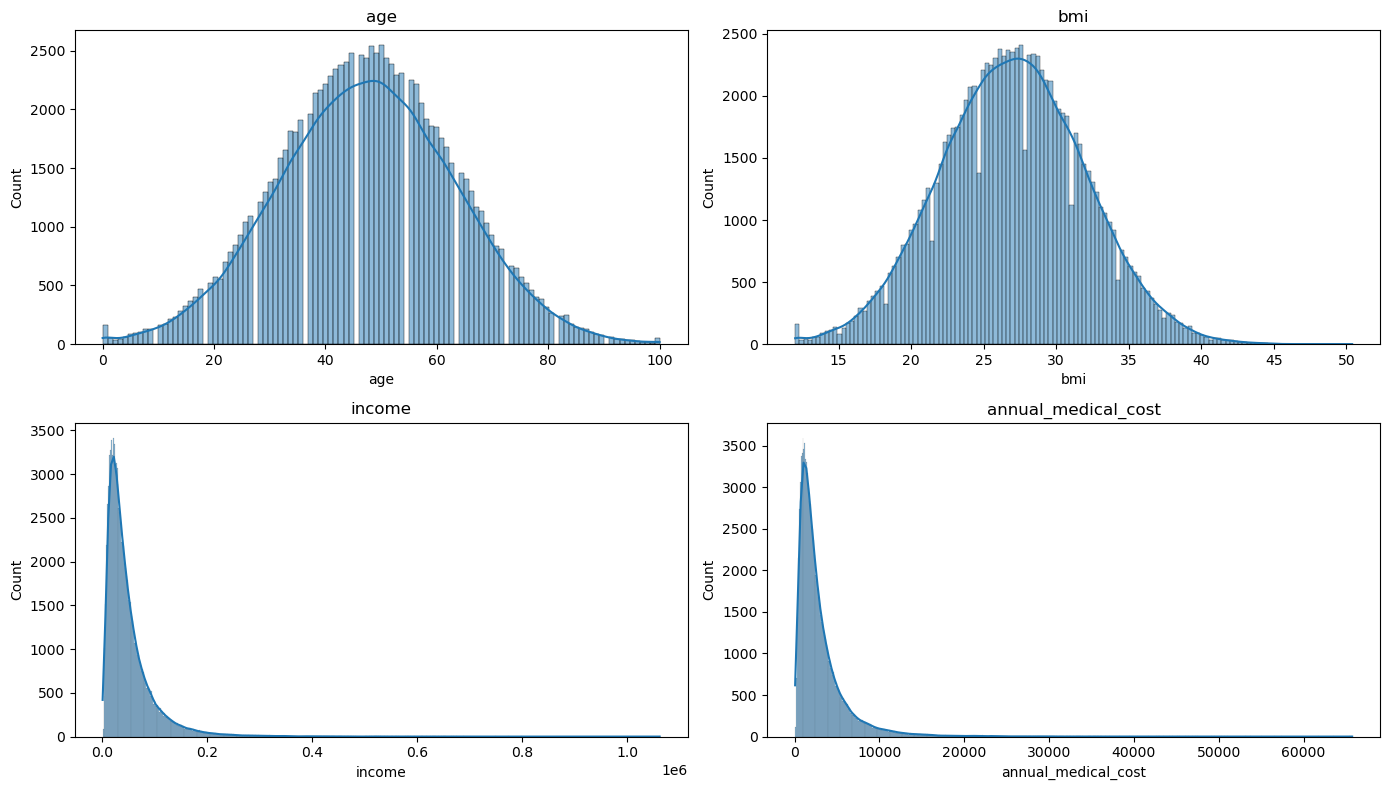

In [19]:
plt.figure(figsize=(14,8))
for i, col in enumerate(['age','bmi','income','annual_medical_cost']):
    plt.subplot(2,2,i+1)
    sns.histplot(mi[col].dropna(), kde=True)
    plt.title(col)
plt.tight_layout()

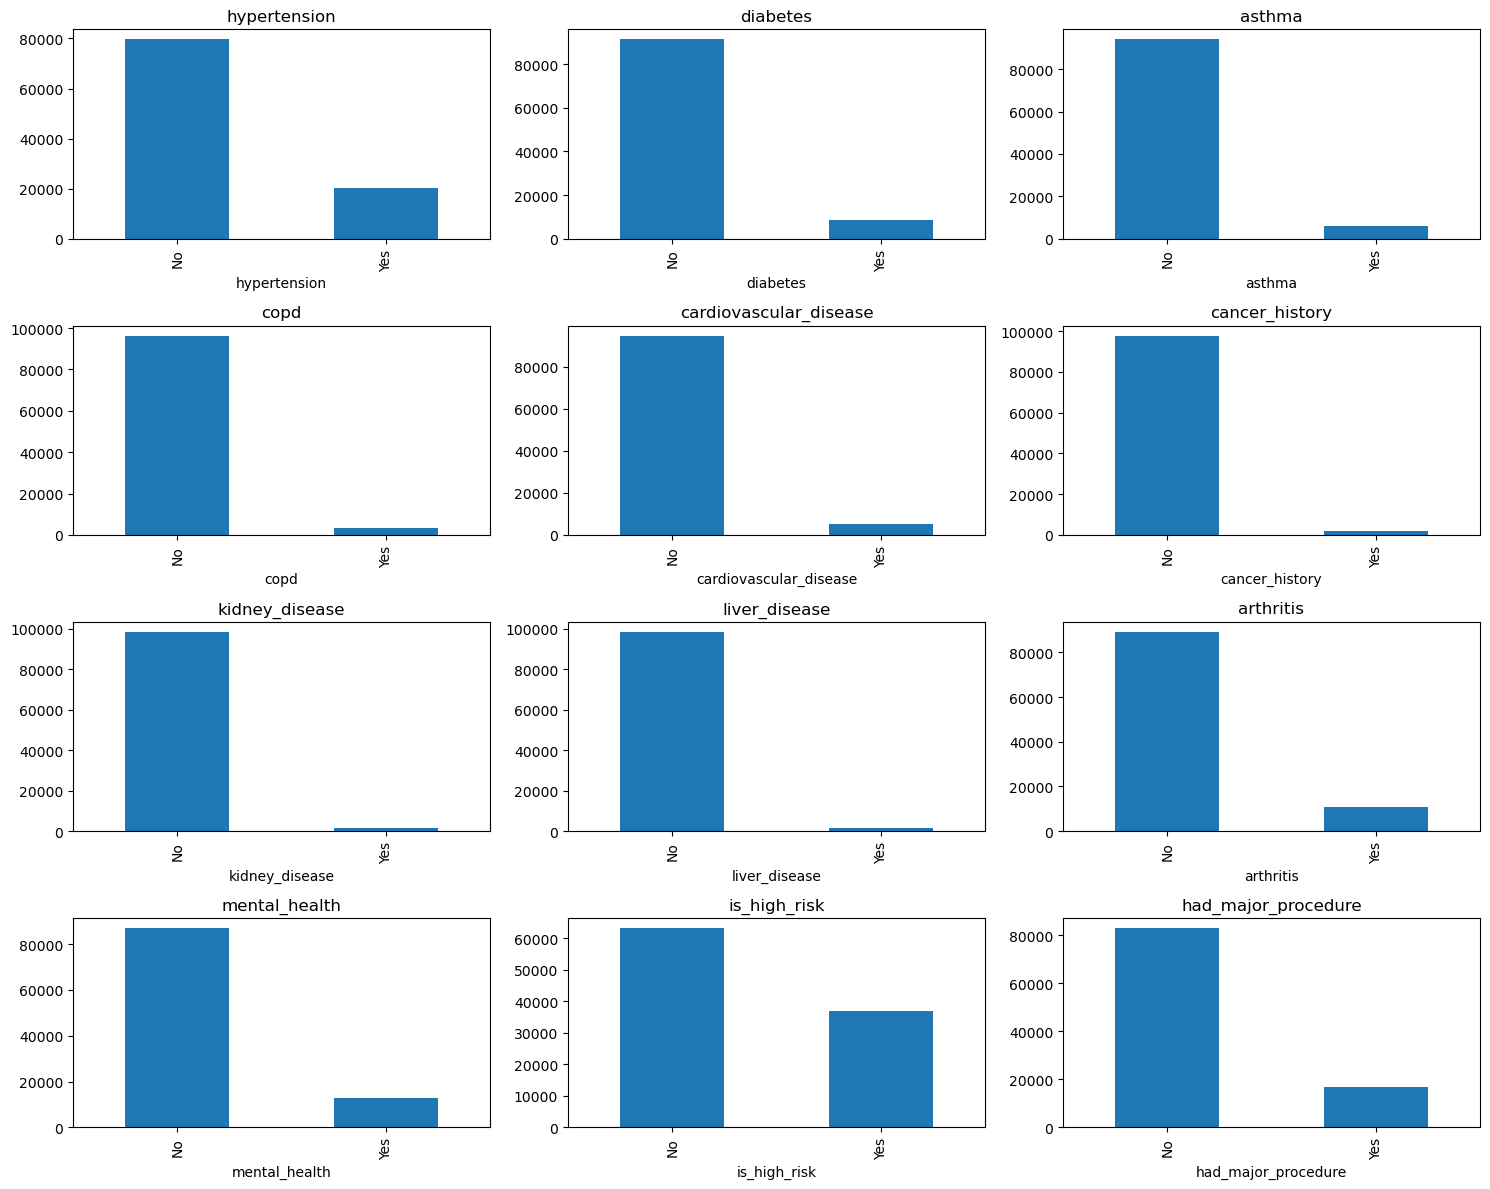

In [20]:
plt.figure(figsize=(15,12))
for i, col in enumerate(binary_cols, 1):
    plt.subplot(4,3,i)
    mi[col].value_counts().plot(kind='bar')
    plt.title(col)

plt.tight_layout()
plt.show()

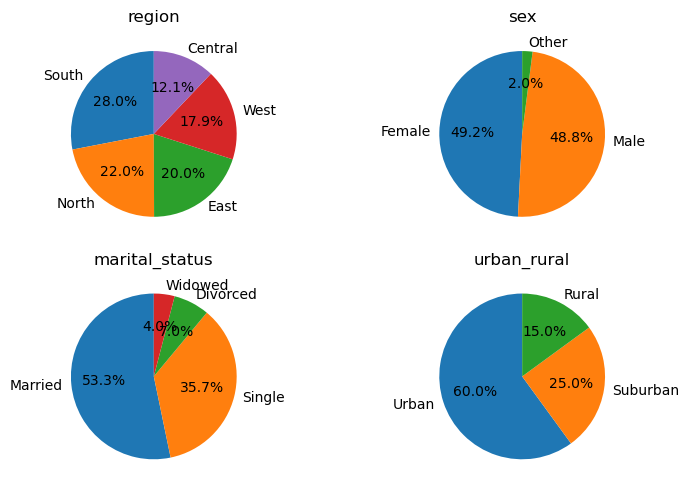

In [21]:
cat_cols = ['region', 'sex', 'marital_status', 'urban_rural']
plt.figure(figsize=(8,5))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(2,2,i)
    mi[col].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90)
    plt.title(col)
    plt.ylabel('')

plt.tight_layout()
plt.show()

### Exploratory Data Analysis: Bivariate Analysis of Numerical and Categorical Features
 - Analysis Using Scatter Plot, Count Plot, and Grouping

In [22]:
mi.groupby(['diabetes','sex'])['annual_medical_cost'].mean()

diabetes  sex   
No        Female    2899.802247
          Male      2911.165227
          Other     2956.765550
Yes       Female    4083.935944
          Male      4154.163967
          Other     3318.503270
Name: annual_medical_cost, dtype: float64

In [23]:
mi.groupby(['smoker','is_high_risk'])['annual_medical_cost'].count()

smoker   is_high_risk
Current  No               3312
         Yes              8816
Former   No              12477
         Yes              5686
Never    No              47430
         Yes             22279
Name: annual_medical_cost, dtype: int64

Text(0.5, 1.0, 'Age Group vs Gender')

<Figure size 800x1000 with 0 Axes>

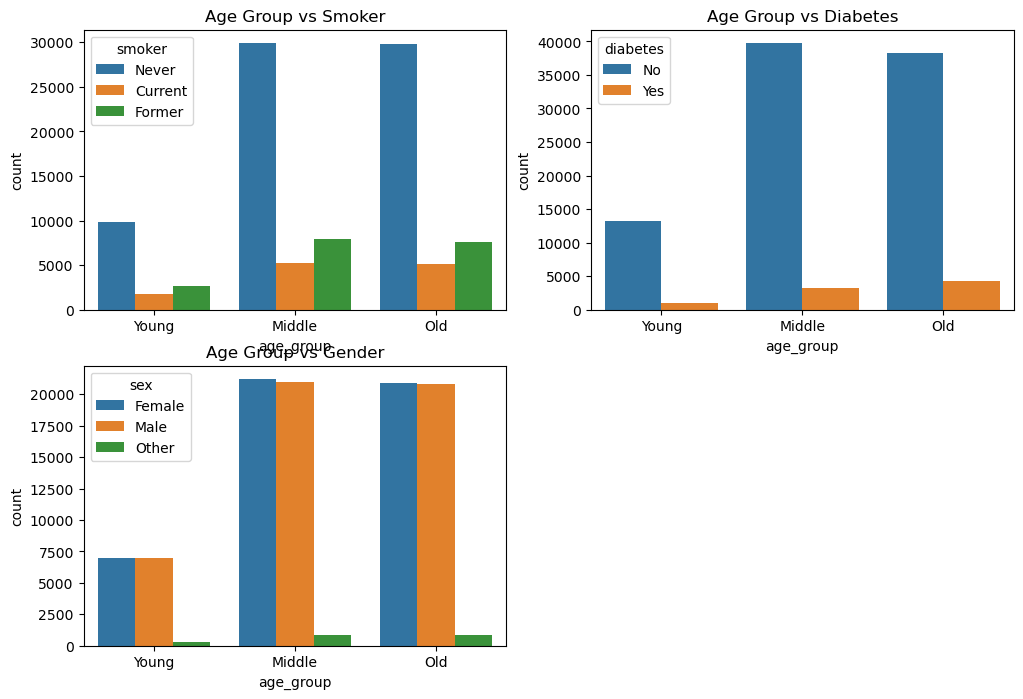

In [24]:
mi['age_group'] = pd.cut(mi['age'],
                        bins=[0,30,50,100],
                        labels=['Young','Middle','Old'])
plt.figure(figsize=(8,10))
mi['age_group'] = pd.cut(mi['age'],
                        bins=[0,30,50,100],
                        labels=['Young','Middle','Old'])
plt.figure(figsize=(12,8))
# Age vs Smoker
plt.subplot(2,2,1)
sns.countplot(data=mi, x='age_group', hue='smoker')
plt.title('Age Group vs Smoker')

# Age vs Diabetes
plt.subplot(2,2,2)
sns.countplot(data=mi, x='age_group', hue='diabetes')
plt.title('Age Group vs Diabetes')

# Age vs Gender
plt.subplot(2,2,3)
sns.countplot(data=mi, x='age_group', hue='sex')
plt.title('Age Group vs Gender')




In [25]:
mi.groupby(['age_group','diabetes','is_high_risk'])['annual_medical_cost'].mean()

C:\Users\Hp\AppData\Local\Temp\ipykernel_28252\1723331519.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mi.groupby(['age_group','diabetes','is_high_risk'])['annual_medical_cost'].mean()


age_group  diabetes  is_high_risk
Young      No        No              2252.466137
                     Yes             4865.364431
           Yes       No              3276.950563
                     Yes             5813.065371
Middle     No        No              2425.781904
                     Yes             4195.510266
           Yes       No              3103.131140
                     Yes             4525.053841
Old        No        No              2371.560001
                     Yes             3860.218632
           Yes       No              3059.695385
                     Yes             4495.746493
Name: annual_medical_cost, dtype: float64

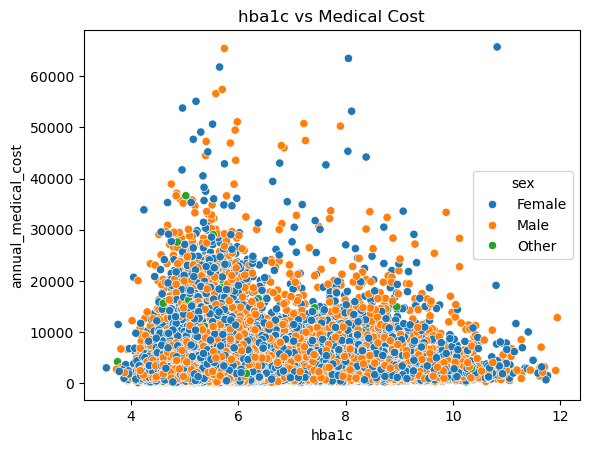

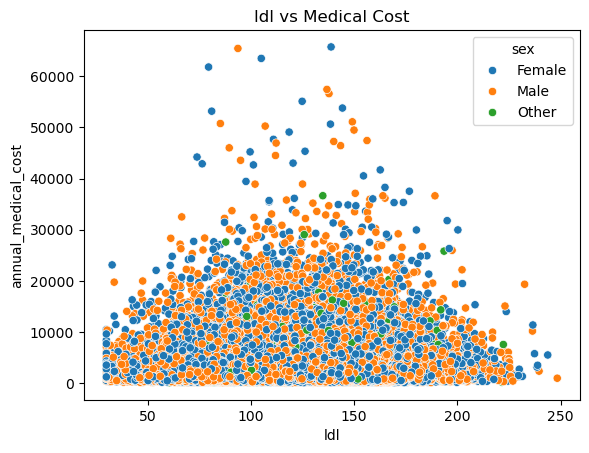

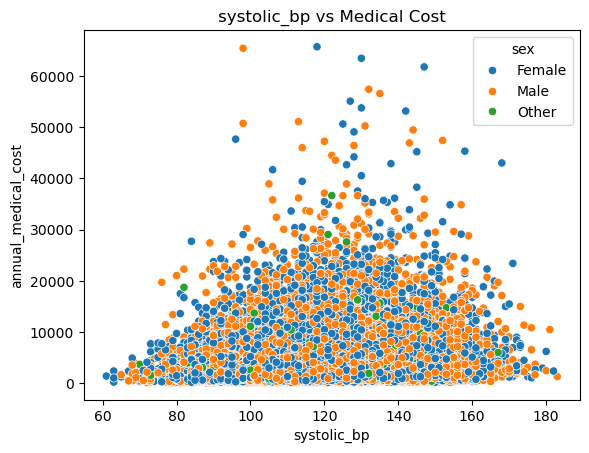

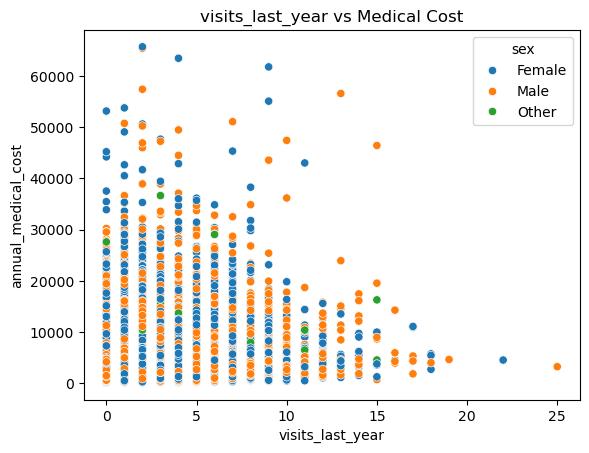

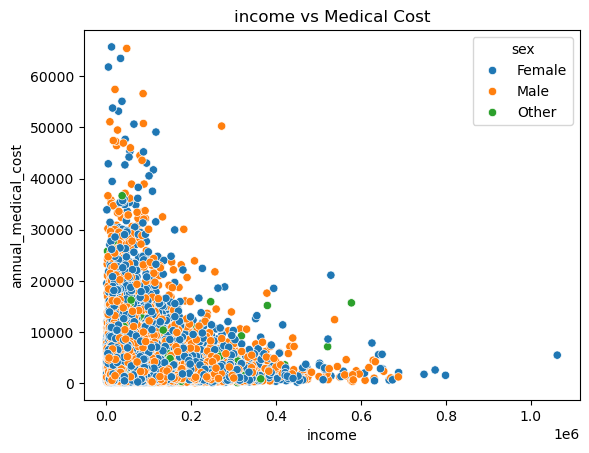

In [33]:
cols = ['hba1c', 'ldl', 'systolic_bp', 'visits_last_year','income']
for col in cols:
    sns.scatterplot(x=mi[col], y=mi['annual_medical_cost'],hue=mi['sex'])
    plt.title(f'{col} vs Medical Cost')
    plt.show()

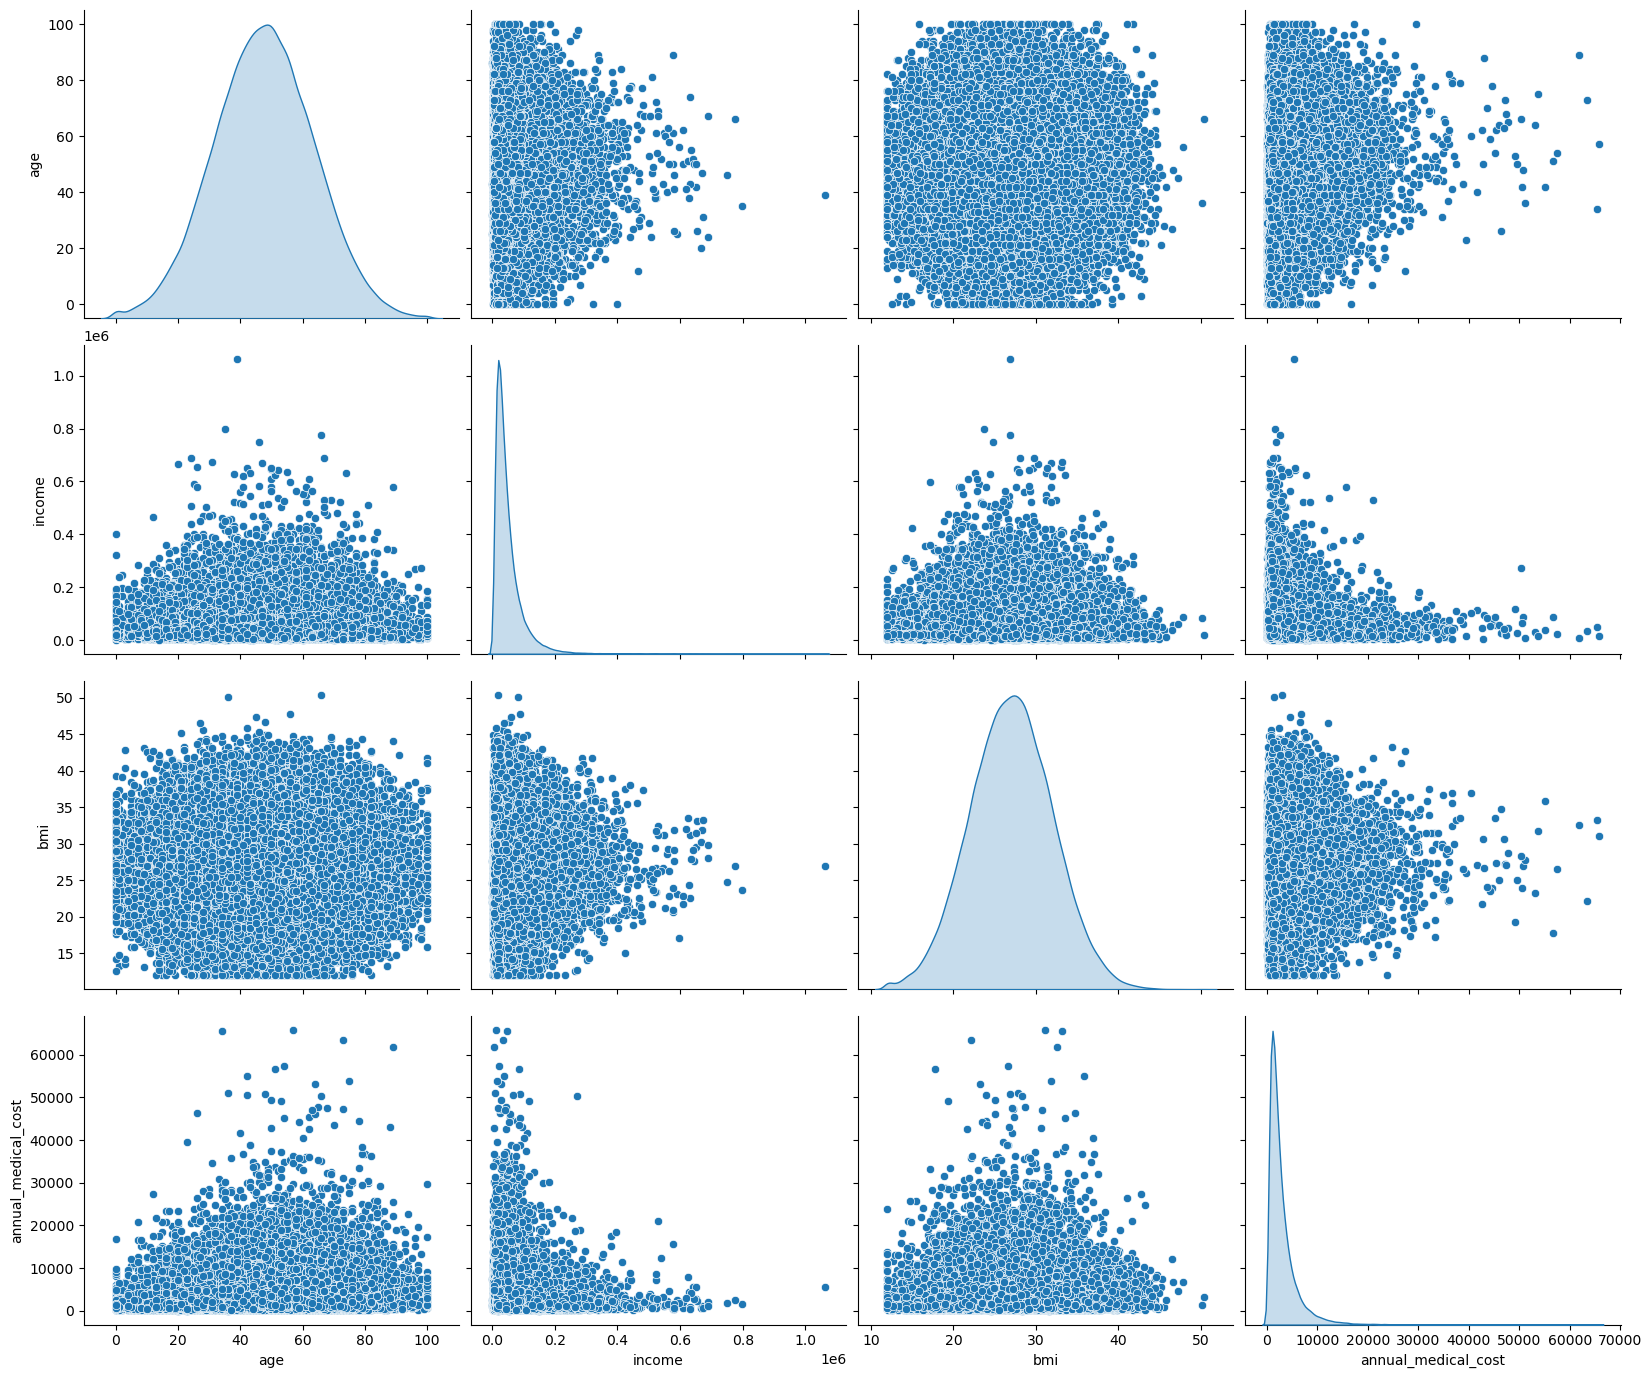

In [27]:
# Select required columns
num_cols = mi[['age','income','bmi','annual_medical_cost']]

# Create pairplot
sns.pairplot(
    num_cols,
    height=3.5,        # size of each plot
    aspect=1.2,        # correct spelling
    diag_kind='kde'    # smooth distribution curve
)

plt.show()

### Multivariate Correlation Analysis with Target Variable

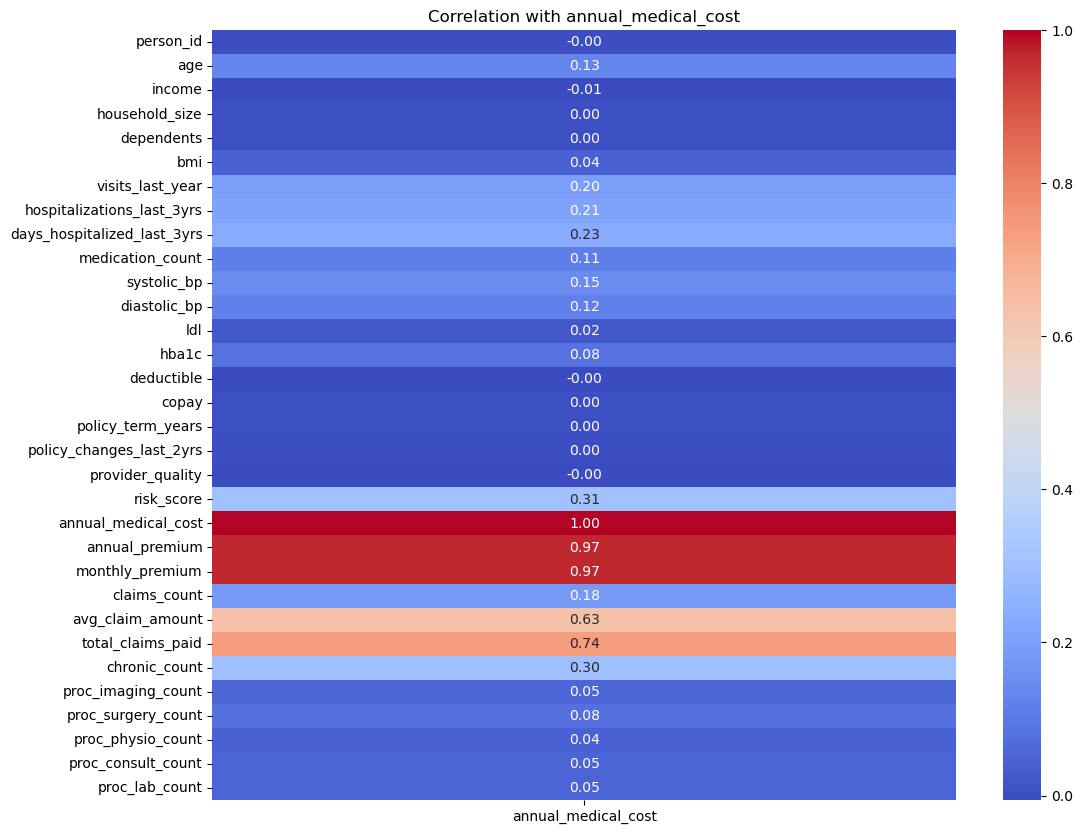

In [28]:
corr_cols = mi.select_dtypes(include=[np.number]).columns.tolist()
corr = mi[corr_cols].corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr.loc[['annual_medical_cost']].T, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation with annual_medical_cost")
plt.show()

### Identifying Outliers in Numerical Features Using Boxplots

ValueError: num must be an integer with 1 <= num <= 25, not 26

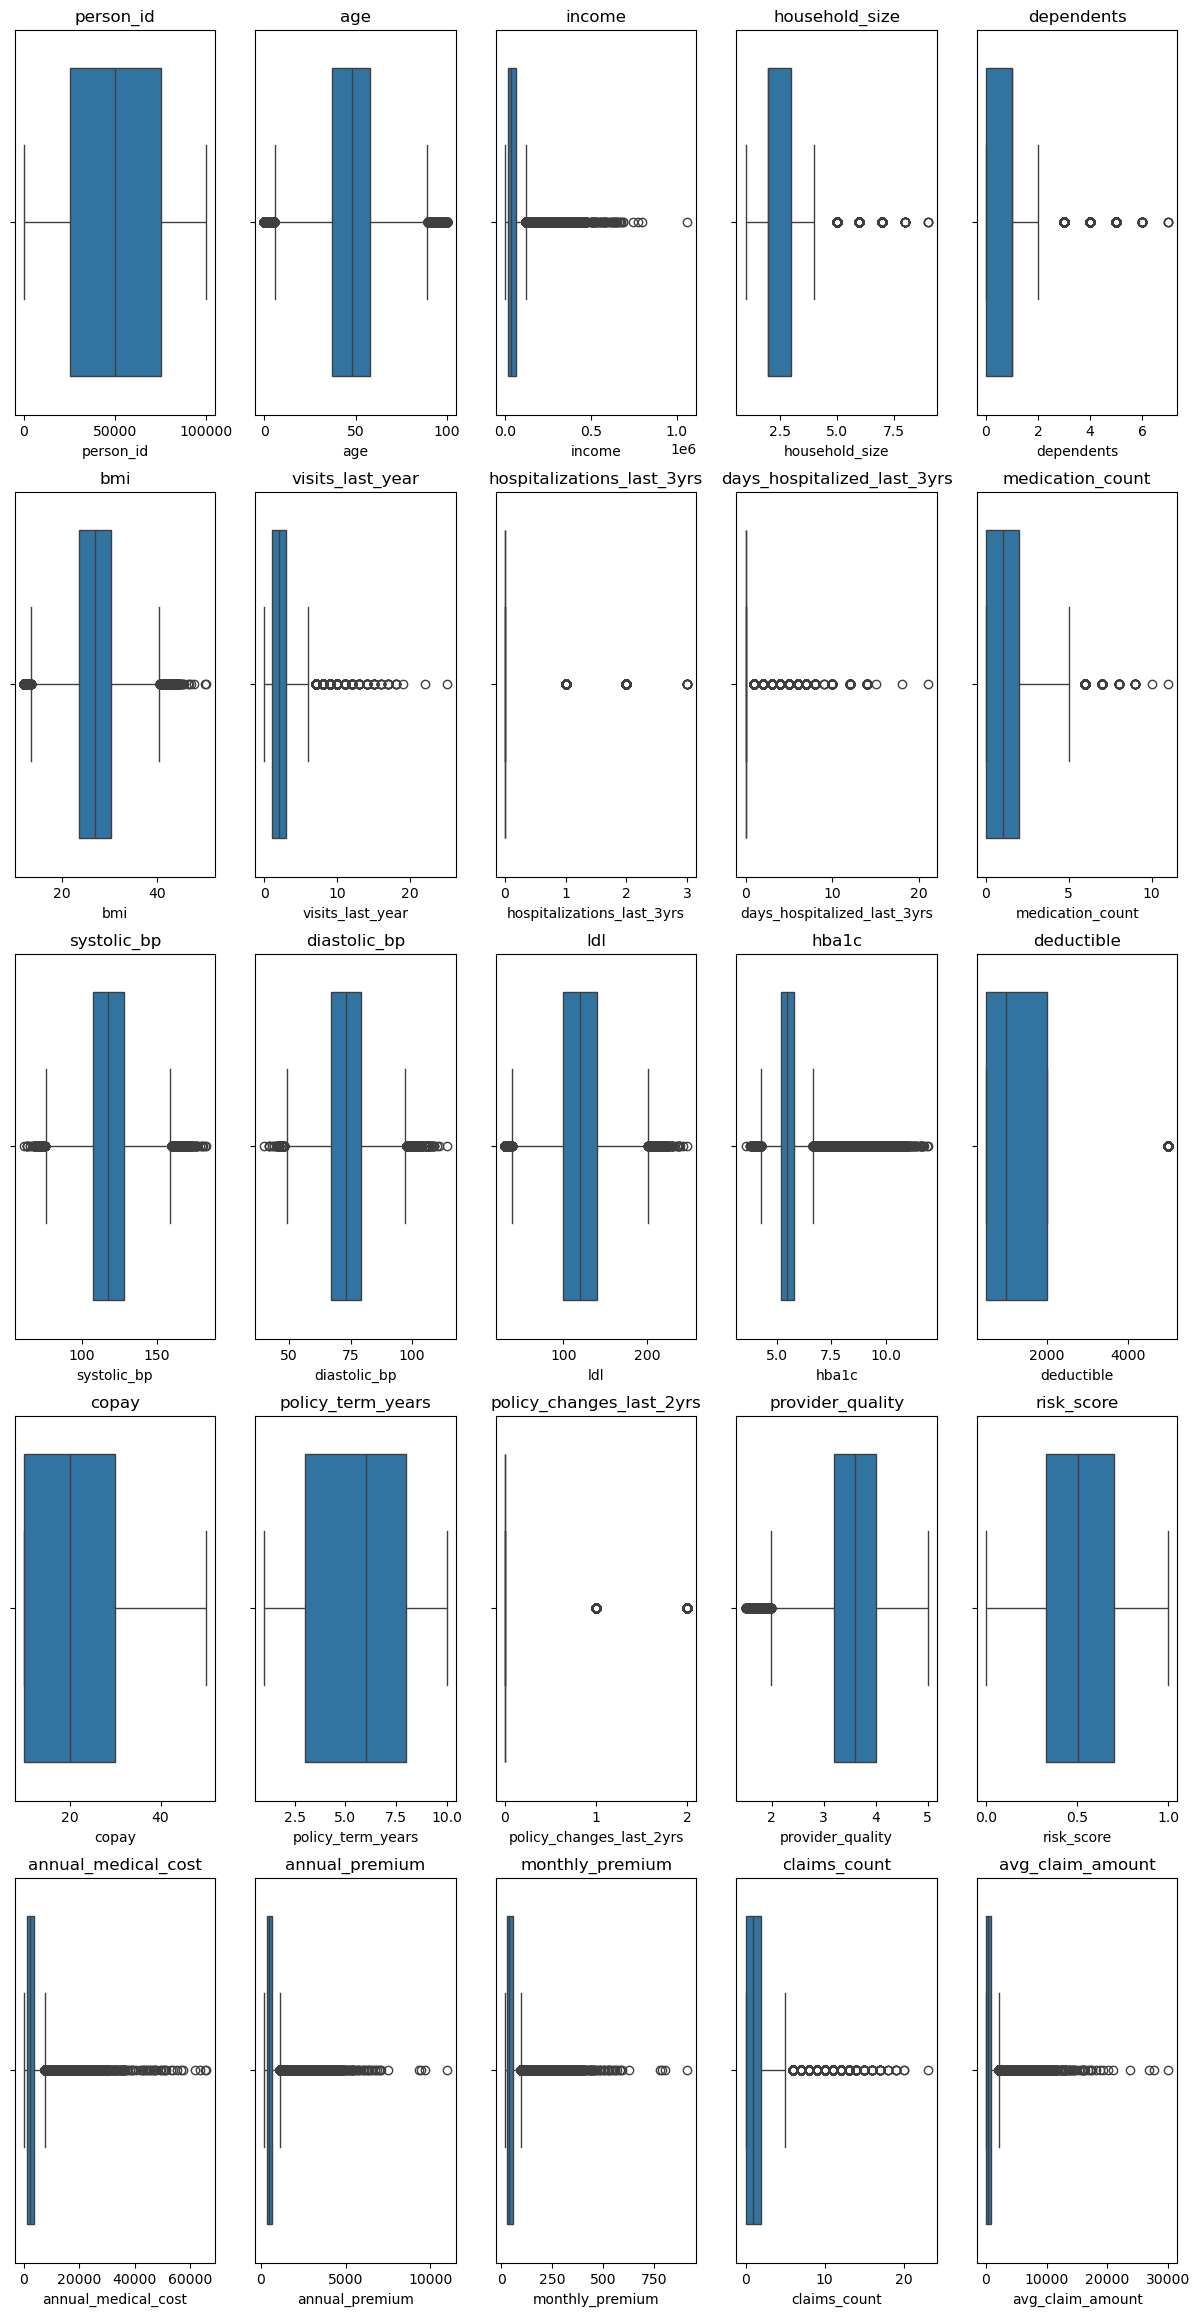

In [29]:
num_cols = mi.select_dtypes(include=['int64','float64']).columns
plt.figure(figsize=(15,29))
for i, col in enumerate(num_cols, 1):
    plt.subplot(5,5,i)  
    sns.boxplot(x=mi[col])
    plt.title(col)
plt.tight_layout()
plt.show()

### Outlier Treatment via Winsorization Technique
  1. Calculate Quartiles
  2. Calculate IQR
  3. Define Outlier Boundaries
  4. Outlier Condition  

In [34]:
cols = ['age','income','bmi','visits_last_year','days_hospitalized_last_3yrs','hba1c','ldl','deductible','annual_medical_cost',
        'annual_premium','monthly_premium','avg_claim_amount','total_claims_paid']

for col in cols:
    Q1 = mi[col].quantile(0.25)
    Q3 = mi[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    mi[col] = mi[col].clip(lower, upper)

### Outlier Removal Completed Using IQR Method

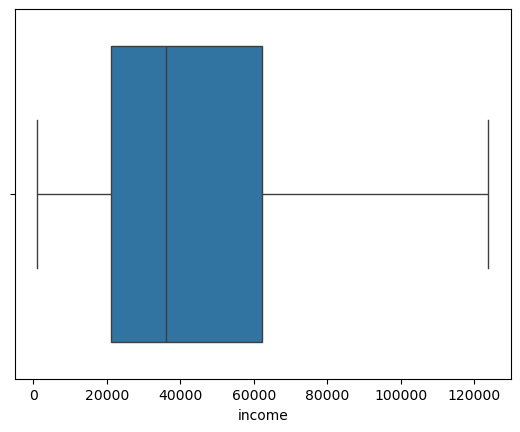

In [35]:
sns.boxplot(x=mi['income'])
plt.show()

In [ ]:
mi.to_csv('cleaned_medical_insurence.csv',index=False)

In [36]:
mi.head()

,person_id,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,...,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure,age_group
0,75722,52.0,Female,North,Suburban,22700.0,Doctorate,Married,Retired,3,...,Yes,No,1,0,2,0,1,No,No,Old
1,80185,79.0,Female,North,Urban,12800.0,No HS,Married,Employed,3,...,Yes,Yes,0,0,1,0,1,Yes,No,Old
2,19865,68.0,Male,North,Rural,40700.0,HS,Married,Retired,5,...,No,Yes,1,0,2,1,0,Yes,No,Old
3,76700,15.0,Male,North,Suburban,15600.0,Some College,Married,Self-employed,5,...,No,No,1,0,0,1,0,No,No,Young
4,92992,53.0,Male,Central,Suburban,89600.0,Doctorate,Married,Self-employed,2,...,Yes,No,2,0,1,1,0,Yes,No,Old


### Insights :


### 1. What is the average age of policyholders

In [37]:
mi['age'].mean()

np.float64(47.51744)

Insight 1: Average age shows your target customer segment

### 2. What is the gender distribution (sex)

In [38]:
mi['sex'].value_counts(normalize=True) * 100

sex
Female    49.193
Male      48.794
Other      2.013
Name: proportion, dtype: float64

Insight 2: Shows % of males vs females → helps understand dataset balance.

### 3.Which region has the most customers?

In [39]:
mi['region'].value_counts()

region
South      28029
North      22027
East       19984
West       17879
Central    12081
Name: count, dtype: int64

Insight 3:Helps identify which region has highest customer base.

### 4. What is the average income?

In [40]:
mi['income'].mean()

np.float64(46122.948)

Insight 4:Higher income groups may afford better insurance plans.

### 5. What is the average BMI?

In [41]:
mi['bmi'].mean()

np.float64(26.988409)

Insight 5: Higher BMI, higher health risk, higher claims.

### 6. What % of people are smokers vs non-smokers?

In [42]:
mi['smoker'].value_counts(normalize=True) * 100

smoker
Never      69.709
Former     18.163
Current    12.128
Name: proportion, dtype: float64

Insight 6: Important risk indicator for insurance pricing

### 7. What is the average annual medical cost?

In [43]:
mi['annual_medical_cost'].mean()

np.float64(2726.4261496000004)

Insight 7: Base cost used for pricing insurance

### 8. What is the most common plan_type?

In [44]:
mi['plan_type'].value_counts()

plan_type
PPO    35167
HMO    34723
EPO    15121
POS    14989
Name: count, dtype: int64

Insight 8: Shows most preferred insurance plan

### 9. What is the average number of hospital visits last year?

In [46]:

mi['visits_last_year'].mean()

np.float64(1.88083)

Insight 9: More visits = more healthcare usage

### 10. What % of people are marked as high risk (is_high_risk)?

In [47]:
mi['is_high_risk'].value_counts(normalize=True) * 100

is_high_risk
No     63.219
Yes    36.781
Name: proportion, dtype: float64

Insight 10: Important for identifying risky customers

### 11. Compare medical cost by gender

In [48]:
mi.groupby('sex')['annual_medical_cost'].mean()

sex
Female    2717.274314
Male      2736.264270
Other     2711.604973
Name: annual_medical_cost, dtype: float64

Insight 11: Compare which gender has higher expenses.

### 12. Compare smokers vs non-smokers → medical cost

In [49]:
mi.groupby('smoker')['annual_medical_cost'].mean()

smoker
Current    3622.556781
Former     2856.147736
Never      2536.717425
Name: annual_medical_cost, dtype: float64

Insight 12: Smokers usually have much higher cost

### 13. Which region has highest avg medical cost?

In [50]:
mi.groupby('region')['annual_medical_cost'].mean()

region
Central    2709.277341
East       2716.562479
North      2716.655182
South      2742.924904
West       2735.211422
Name: annual_medical_cost, dtype: float64

Insight 13: Healthcare cost varies by region

### 14. Does BMI affect medical cost?

In [51]:
mi[['bmi','annual_medical_cost']].corr()

,bmi,annual_medical_cost
bmi,1.000000,0.054978
annual_medical_cost,0.054978,1.000000


Insight 14: Positive correlation → obesity increases cost

### 15. Which plan_type has highest claims_count

In [52]:
mi.groupby('plan_type')['claims_count'].mean()


plan_type
EPO    1.626347
HMO    1.633010
POS    1.598772
PPO    1.618534
Name: claims_count, dtype: float64

Insight 15: Which plan has more usage

### 16. Compare urban vs rural healthcare costs

In [53]:
mi.groupby('urban_rural')['annual_medical_cost'].mean()

urban_rural
Rural       2729.245727
Suburban    2731.327571
Urban       2723.680030
Name: annual_medical_cost, dtype: float64

Insighr 16: Urban areas usually cost more

### 17. Does education level impact risk_score?

In [54]:
mi.groupby('education')['risk_score'].mean()

education
Bachelors       0.521103
Doctorate       0.514479
HS              0.518188
Masters         0.522801
No HS           0.528482
Some College    0.517322
Name: risk_score, dtype: float64

Insight 17: Lifestyle awareness affects health

### 18. Compare married vs single → medical expenses

In [55]:
mi.groupby('marital_status')['annual_medical_cost'].mean()


marital_status
Divorced    2717.917633
Married     2725.887164
Single      2731.076114
Widowed     2707.174992
Name: annual_medical_cost, dtype: float64

Insight 18: Families may have higher costs

### 19. Does employment_status affect premium?

In [56]:
mi.groupby('employment_status')['annual_premium'].mean()

employment_status
Employed         544.447240
Retired          544.850016
Self-employed    544.112912
Unemployed       549.540470
Name: annual_premium, dtype: float64

Insight 19: Stable jobs = higher premium plans

### 20. Relationship between age and risk_score

In [57]:
mi[['age','risk_score']].corr()

,age,risk_score
age,1.000000,0.721939
risk_score,0.721939,1.000000


Insight 20: Risk increases with age.

### 21. Correlation between bmi and hba1c (diabetes indicator)

In [58]:
mi[['bmi','hba1c']].corr()

,bmi,hba1c
bmi,1.000000,0.002881
hba1c,0.002881,1.000000


Insight 21: Higher BMI = higher diabetes risk

### 22. Compare chronic_count vs medical cost

In [59]:
mi.groupby('chronic_count')['annual_medical_cost'].mean()

chronic_count
0    2086.046711
1    3022.050384
2    3776.003059
3    4434.075383
4    5022.327587
5    3885.147778
6    7507.217500
Name: annual_medical_cost, dtype: float64

Insight 22: More diseases = higher cost

### 23. Which group has more hospitalizations (smokers/non-smokers)?

In [60]:
mi.groupby('smoker')['hospitalizations_last_3yrs'].mean()

smoker
Current    0.094822
Former     0.093267
Never      0.093532
Name: hospitalizations_last_3yrs, dtype: float64

Insight 23: Smokers get hospitalized more

### 24. Compare high-risk vs low-risk → claims_count

In [61]:
mi.groupby('is_high_risk')['claims_count'].mean()

is_high_risk
No     1.211060
Yes    2.327724
Name: claims_count, dtype: float64

Insight 24: High-risk = more claims

### 25. Does BMI affect medical cost

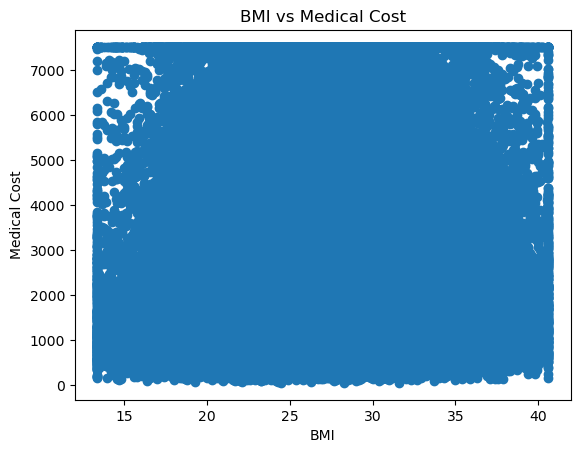

In [62]:
plt.scatter(mi['bmi'], mi['annual_medical_cost'])
plt.xlabel("BMI")
plt.ylabel("Medical Cost")
plt.title("BMI vs Medical Cost")
plt.show()

Insight 25: There is a positive relationship between BMI and medical cost.
As BMI increases, medical expenses also increase
Customers with higher BMI are more likely to have health issues → insurance companies should adjust premiums based on BMI

### 26. How does age impact risk score? (Scatter Plot)

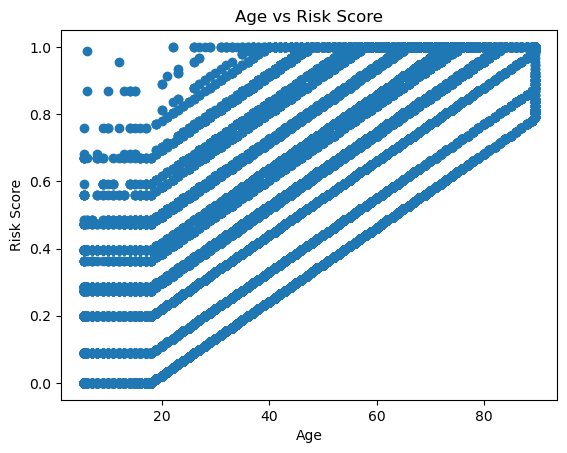

In [63]:
plt.scatter(mi['age'], mi['risk_score'])
plt.xlabel("Age")
plt.ylabel("Risk Score")
plt.title("Age vs Risk Score")
plt.show()

Insight 26: Risk score increases with age, showing older individuals are more prone to health risks.

### 27. What is the distribution of smokers vs non-smokers?

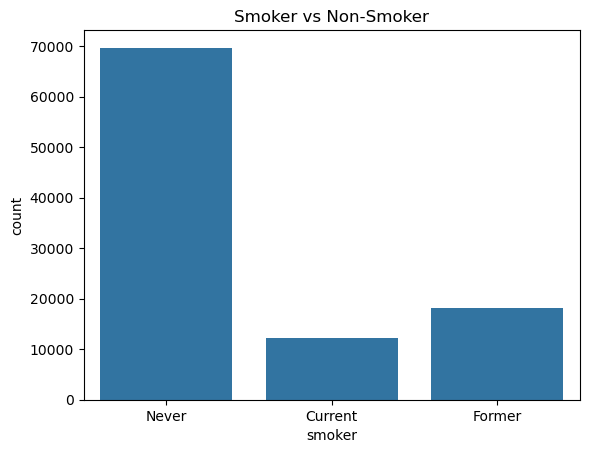

In [65]:
sns.countplot(x='smoker', data=mi)
plt.title("Smoker vs Non-Smoker")
plt.show()

Non-smokers are usually more than smokers, but smokers represent a high-risk group

### 28. Which insurance plan is most preferred?

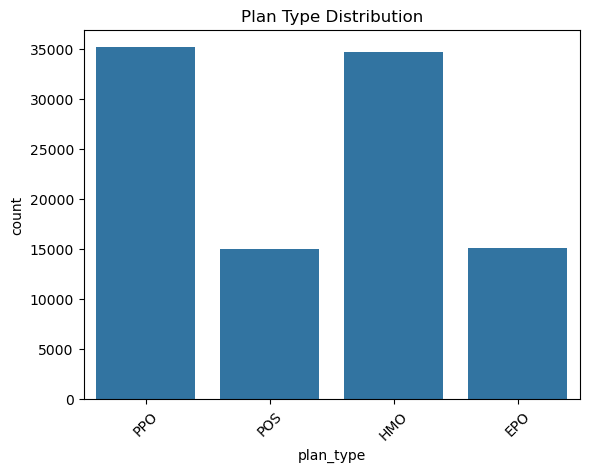

In [66]:
sns.countplot(x='plan_type', data=mi)
plt.xticks(rotation=45)
plt.title("Plan Type Distribution")
plt.show()

Insight 28: One or two plans dominate customer preference.

### 29. How is medical cost distributed among customers

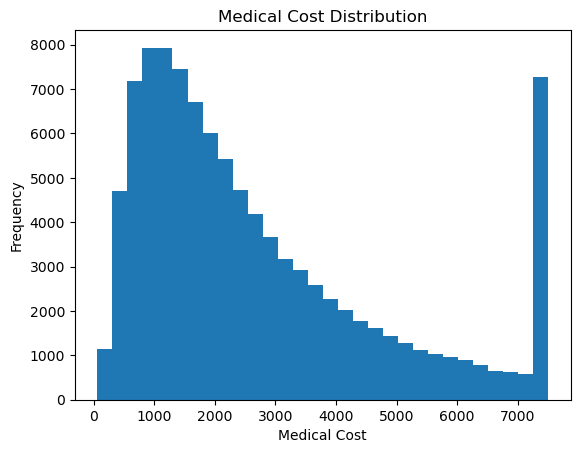

In [67]:
plt.hist(mi['annual_medical_cost'], bins=30)
plt.xlabel("Medical Cost")
plt.ylabel("Frequency")
plt.title("Medical Cost Distribution")
plt.show()

Insight 29: A small number of customers drive majority of healthcare expenses

### 30. Which region has the highest customer share

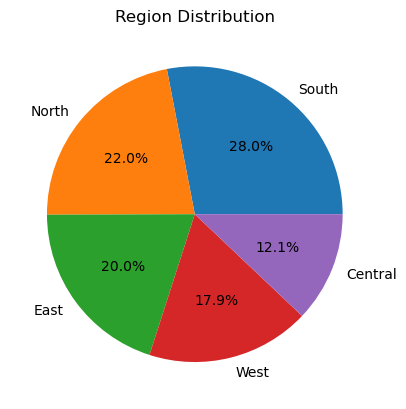

In [68]:
mi['region'].value_counts().plot.pie(autopct='%1.1f%%')
plt.title("Region Distribution")
plt.ylabel("")
plt.show()

Insight 30: One region contributes the largest percentage of customers


### 31. Do more doctor visits lead to higher medical cost

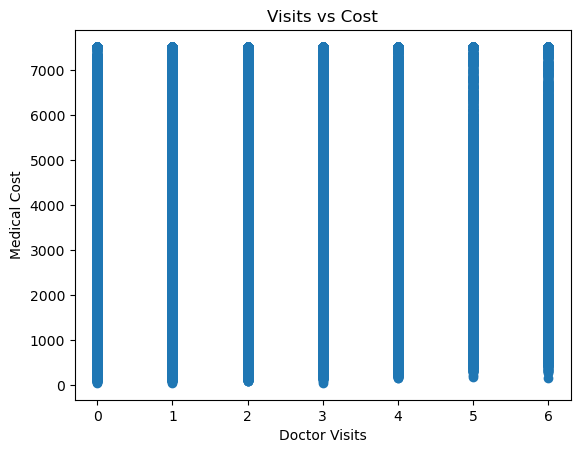

In [69]:
plt.scatter(mi['visits_last_year'], mi['annual_medical_cost'])
plt.xlabel("Doctor Visits")
plt.ylabel("Medical Cost")
plt.title("Visits vs Cost")
plt.show()

Insight 31: There is a positive trend = more visits lead to higher cost,
            Frequent healthcare usage drives insurance expenses

### 32. Does higher income lead to higher medical spending

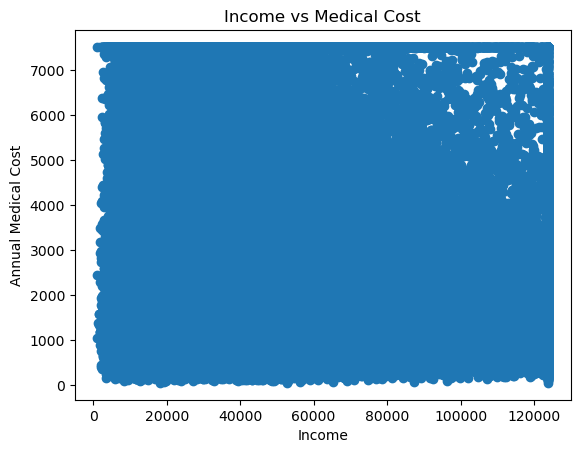

In [70]:
plt.scatter(mi['income'], mi['annual_medical_cost'])
plt.xlabel("Income")
plt.ylabel("Annual Medical Cost")
plt.title("Income vs Medical Cost")
plt.show()

### 33. Do higher-income customers choose higher premium plans

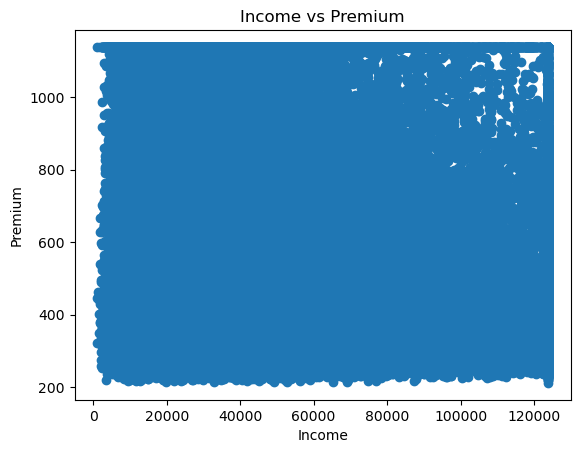

In [71]:
plt.scatter(mi['income'], mi['annual_premium'])
plt.xlabel("Income")
plt.ylabel("Premium")
plt.title("Income vs Premium")
plt.show()

Insight 33: Clear upward trend → as income increases, premium also increases, High-income customers are willing to invest in better insurance plans

### 34.How are customers distributed across network tiers based on employment status?

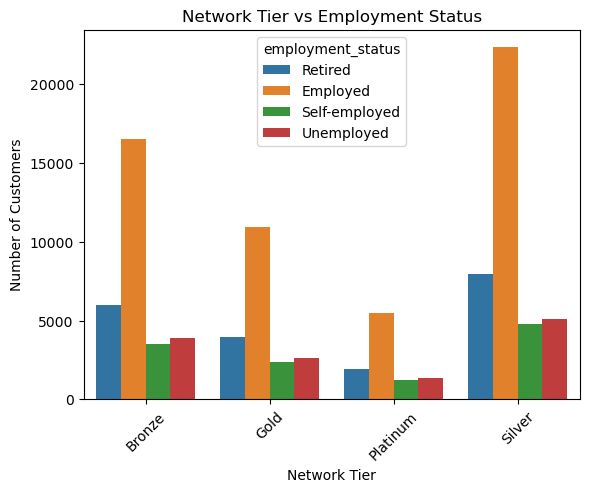

In [73]:
sns.countplot(x='network_tier', hue='employment_status', data=mi)
plt.title("Network Tier vs Employment Status")
plt.xlabel("Network Tier")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.show()

Insight 34: Salaried customers are more concentrated in higher network tiers, indicating a preference for better hospital coverage and services

### 35. How does household size distribution vary across different marital statuses

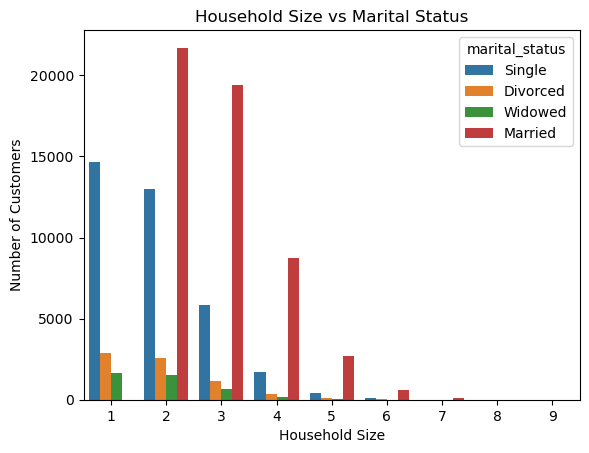

In [74]:
sns.countplot(x='household_size', hue='marital_status', data=mi)
plt.title("Household Size vs Marital Status")
plt.xlabel("Household Size")
plt.ylabel("Number of Customers")
plt.show()

Insight 35: Single customers are highly concentrated in smaller household sizes, Married customers dominate medium to larger household sizes,Divorced and widowed customers are present but in much lower numbers, mostly in smaller households

### 36. How do alcohol consumption and smoking habits impact hospitalizations in the last 3 years

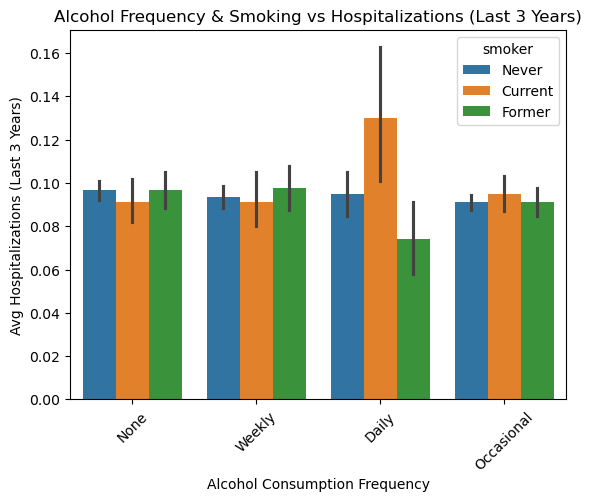

In [75]:
sns.barplot(x='alcohol_freq',y='hospitalizations_last_3yrs',hue='smoker',data=mi)

plt.title("Alcohol Frequency & Smoking vs Hospitalizations (Last 3 Years)")
plt.xlabel("Alcohol Consumption Frequency")
plt.ylabel("Avg Hospitalizations (Last 3 Years)")
plt.xticks(rotation=45)
plt.show()

Insight 36: Customers who smoke AND consume alcohol frequently tend to have higher average hospitalizations
Non-smokers with low alcohol consumption show lower hospitalization rates
There is a combined effect of smoking + alcohol on health outcomes

### 37. Is there a relationship between average claim amount and total claims paid?

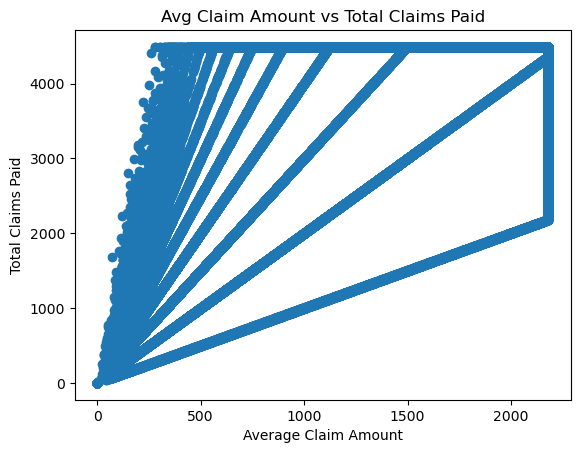

In [76]:
plt.scatter(mi['avg_claim_amount'], mi['total_claims_paid'])
plt.xlabel("Average Claim Amount")
plt.ylabel("Total Claims Paid")
plt.title("Avg Claim Amount vs Total Claims Paid")
plt.show()

Insight 37: There is usually a clear positive relationship,
As average claim amount increases, total claims paid also increases

### 38. What is the distribution of customers across city tiers?

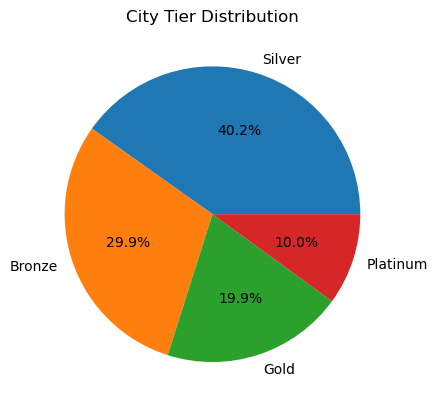

In [77]:
mi['network_tier'].value_counts().plot.pie(autopct='%1.1f%%')
plt.title("City Tier Distribution")
plt.ylabel("")
plt.show()

Insight 38: Majority of customers prefer mid-range plans (Silver & Bronze), Very few customers opt for premium plans (Platinum)

### 39. What is the education distribution of customers.

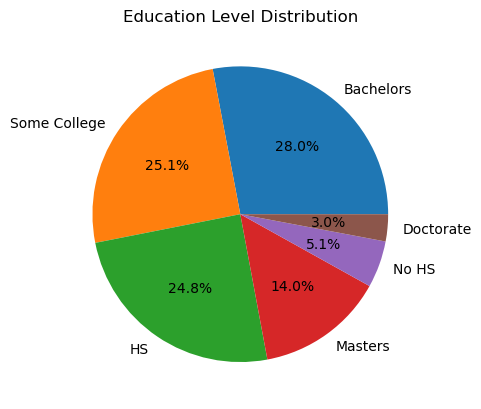

In [78]:
mi['education'].value_counts().plot.pie(autopct='%1.1f%%')
plt.title("Education Level Distribution")
plt.ylabel("")
plt.show()

Insight 39: Majority of customers belong to mid-level education categories (High School, Some College, Bachelors)
Highly educated (Masters, Doctorate) and very low education (No HS) groups form a small portion of the dataset
The dataset is heavily concentrated around moderately educated individuals